In [34]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from pathlib import Path

In [35]:
#loading data
miso = pd.read_parquet('cleaned_data/merged.parquet')
print(miso.shape)
miso.head()

(366313, 38)


,interval_start_utc,interval_end_utc,publish_time_utc,north_derated_outages_mw,north_forced_outages_mw,north_planned_outages_mw,north_unplanned_outages_mw,central_derated_outages_mw,central_forced_outages_mw,central_planned_outages_mw,...,south_wind,miso_wind,north_solar,central_solar,south_solar,miso_solar,lmp_dam,energy_dam,congestion_dam,loss_dam
0,2023-03-25 01:55:00+00:00,2023-03-25 02:00:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,9920.8,3.9,1.0,1.2,6.1,26.92,26.09,1.66,-0.83
1,2023-03-25 02:00:00+00:00,2023-03-25 02:05:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
2,2023-03-25 02:05:00+00:00,2023-03-25 02:10:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
3,2023-03-25 02:10:00+00:00,2023-03-25 02:15:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
4,2023-03-25 02:15:00+00:00,2023-03-25 02:20:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85


In [36]:
#summary stats
miso['lmp_rtm'].describe()

count    360711.000000
mean         34.408384
std          83.799619
min        -161.250000
25%          18.650000
50%          24.870000
75%          33.930000
max       10000.000000
Name: lmp_rtm, dtype: float64

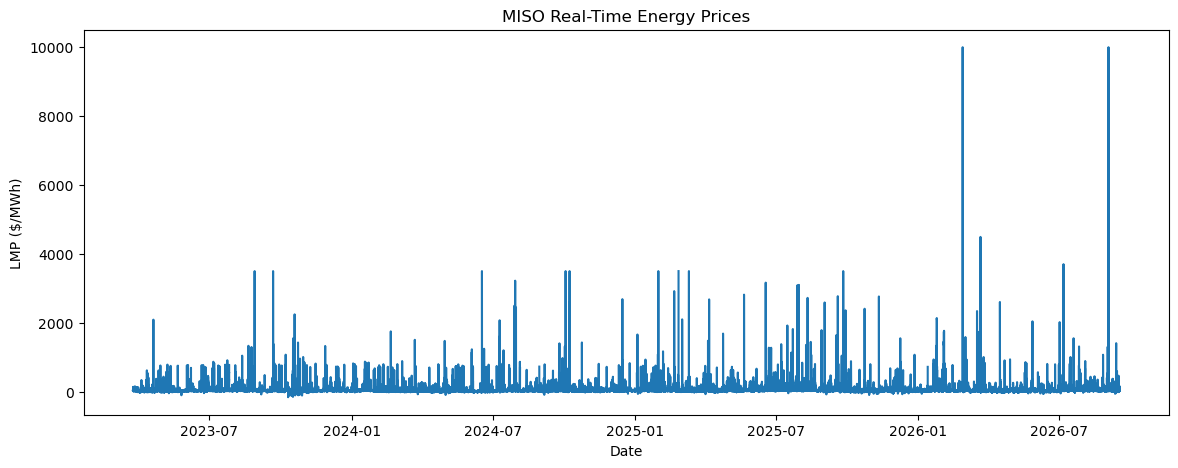

In [37]:
#plotting original lmp prices 
plt.figure(figsize=(14, 5))
plt.plot(miso['interval_start_utc'], miso['lmp_rtm'])
plt.xlabel('Date')
plt.ylabel('LMP ($/MWh)')
plt.title("MISO Real-Time Energy Prices")
plt.show()


In [38]:
#investigating outliers

#count prices above 132 threshold
outliers = miso['lmp_rtm'] > 132
print("Number of lmp prices above $132:", outliers.sum())

Number of lmp prices above $132: 7769


In [39]:
#data frame of outliers
lmp_outliers = miso[miso['lmp_rtm']>132].copy()
lmp_outliers.head(10)

,interval_start_utc,interval_end_utc,publish_time_utc,north_derated_outages_mw,north_forced_outages_mw,north_planned_outages_mw,north_unplanned_outages_mw,central_derated_outages_mw,central_forced_outages_mw,central_planned_outages_mw,...,south_wind,miso_wind,north_solar,central_solar,south_solar,miso_solar,lmp_dam,energy_dam,congestion_dam,loss_dam
100,2023-03-25 10:15:00+00:00,2023-03-25 10:20:00+00:00,2023-03-24 05:00:00+00:00,343.0,135.0,2718.0,961.0,1758.0,2704.0,18109.0,...,0.0,10404.6,0.0,0.0,0.0,0.0,23.57,21.57,1.55,0.45
731,2023-03-27 14:50:00+00:00,2023-03-27 14:55:00+00:00,2023-03-26 05:00:00+00:00,369.0,175.0,2837.0,986.0,2446.0,2937.0,17914.0,...,0.0,5808.8,165.6,599.4,212.8,977.8,43.78,37.24,7.13,-0.59
732,2023-03-27 14:55:00+00:00,2023-03-27 15:00:00+00:00,2023-03-26 05:00:00+00:00,369.0,175.0,2837.0,986.0,2446.0,2937.0,17914.0,...,0.0,5808.8,165.6,599.4,212.8,977.8,43.78,37.24,7.13,-0.59
3009,2023-04-04 12:40:00+00:00,2023-04-04 12:45:00+00:00,2023-04-03 05:00:00+00:00,1091.0,108.0,7550.0,415.0,2341.0,1909.0,23357.0,...,0.0,19611.4,0.4,10.0,1.5,11.9,31.21,26.45,6.62,-1.86
3140,2023-04-04 23:35:00+00:00,2023-04-04 23:40:00+00:00,2023-04-03 05:00:00+00:00,1091.0,108.0,7550.0,415.0,2341.0,1909.0,23357.0,...,0.0,22519.0,82.4,389.2,125.4,597.0,20.49,27.10,-4.35,-2.26
3728,2023-04-07 00:35:00+00:00,2023-04-07 00:40:00+00:00,2023-04-05 05:00:00+00:00,1185.0,128.0,8340.0,573.0,2734.0,2939.0,22087.0,...,0.0,6851.6,140.9,346.9,13.1,500.9,42.17,43.09,0.90,-1.82
3760,2023-04-07 03:15:00+00:00,2023-04-07 03:20:00+00:00,2023-04-05 05:00:00+00:00,1185.0,128.0,8340.0,573.0,2734.0,2939.0,22087.0,...,0.0,9577.8,0.0,0.0,0.0,0.0,25.90,25.28,0.58,0.04
4751,2023-04-10 13:50:00+00:00,2023-04-10 13:55:00+00:00,2023-04-09 05:00:00+00:00,722.0,1431.0,7217.0,432.0,1753.0,3290.0,21198.0,...,0.0,9797.0,96.0,542.1,119.3,757.4,28.31,32.58,-2.64,-1.63
4862,2023-04-10 23:05:00+00:00,2023-04-10 23:10:00+00:00,2023-04-09 05:00:00+00:00,722.0,1431.0,7217.0,432.0,1753.0,3290.0,21198.0,...,0.0,5313.7,262.0,858.4,235.6,1356.0,26.48,30.29,-2.01,-1.80
4863,2023-04-10 23:10:00+00:00,2023-04-10 23:15:00+00:00,2023-04-09 05:00:00+00:00,722.0,1431.0,7217.0,432.0,1753.0,3290.0,21198.0,...,0.0,5313.7,262.0,858.4,235.6,1356.0,26.48,30.29,-2.01,-1.80


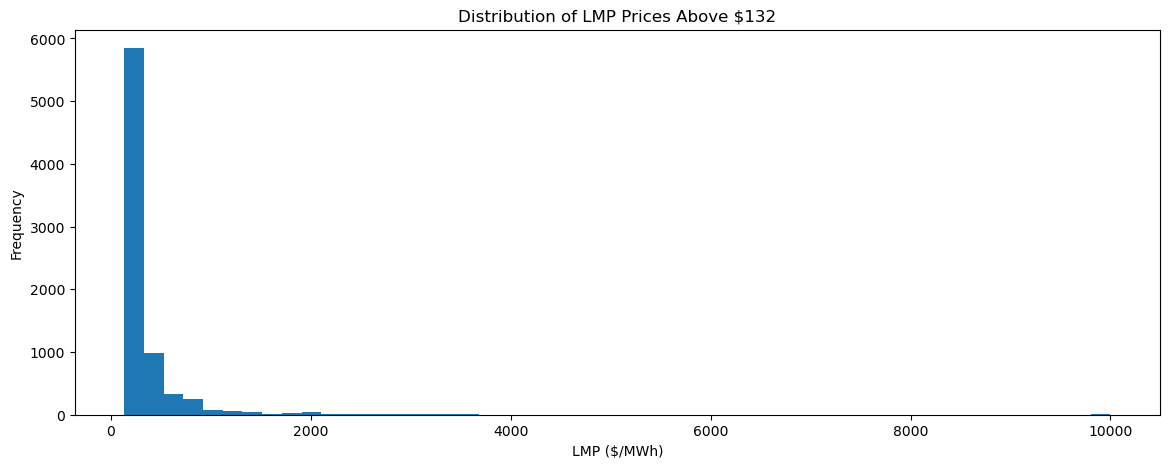

In [40]:
#view distribution of LMP outliers
plt.figure(figsize=(14, 5))
plt.hist(lmp_outliers["lmp_rtm"], bins=50)
plt.xlabel("LMP ($/MWh)")
plt.ylabel("Frequency")
plt.title("Distribution of LMP Prices Above $132")
plt.show()

In [41]:
#Outliers over time
lmp_outliers[['interval_start_utc', 'lmp_rtm']].head(20)

,interval_start_utc,lmp_rtm
100,2023-03-25 10:15:00+00:00,140.90
731,2023-03-27 14:50:00+00:00,156.21
732,2023-03-27 14:55:00+00:00,145.49
3009,2023-04-04 12:40:00+00:00,137.46
3140,2023-04-04 23:35:00+00:00,337.28
3728,2023-04-07 00:35:00+00:00,171.72
3760,2023-04-07 03:15:00+00:00,133.00
4751,2023-04-10 13:50:00+00:00,141.65
4862,2023-04-10 23:05:00+00:00,141.20
4863,2023-04-10 23:10:00+00:00,139.86


In [42]:
#prices surrounding a potential outlier
outlier_time = pd.Timestamp('2023-04-04 23:35:00+00:00', tz='UTC')
start_time = outlier_time - pd.Timedelta(minutes=30)
end_time = outlier_time + pd.Timedelta(minutes=30)
miso.loc[miso['interval_start_utc'].between(start_time, end_time),
         ['interval_start_utc', 'lmp_rtm']]

,interval_start_utc,lmp_rtm
3134,2023-04-04 23:05:00+00:00,30.08
3135,2023-04-04 23:10:00+00:00,27.38
3136,2023-04-04 23:15:00+00:00,32.34
3137,2023-04-04 23:20:00+00:00,29.74
3138,2023-04-04 23:25:00+00:00,18.18
3139,2023-04-04 23:30:00+00:00,119.45
3140,2023-04-04 23:35:00+00:00,337.28
3141,2023-04-04 23:40:00+00:00,30.68
3142,2023-04-04 23:45:00+00:00,79.99
3143,2023-04-04 23:50:00+00:00,94.73


Creating two outlier datasets. One with all outliers above 132 and one with suspicious spikes.

In [43]:
#creating  both datasets
miso_selective = miso.copy()    #suspicous outliers
miso_all_outliers = miso.copy() #all about $132

miso_selective['lmp_org'] = miso_selective['lmp_rtm']
miso_all_outliers['lmp_org'] = miso_all_outliers['lmp_rtm']

#flagging outliers
miso_selective['lmp_flagged'] = (miso_selective['lmp_rtm'] > 132)
miso_all_outliers['lmp_flagged'] = (miso_all_outliers['lmp_rtm'] > 132)

Selective outliers

In [44]:
#Replacing outliers selectively: identify potentially legitimate spikes and suspicious price spikes
miso_selective ['rolling_median'] = (
    miso_selective['lmp_rtm']
    .rolling(window=13, center=True, min_periods=7)
    .median()
)
miso_selective[
    ["interval_start_utc", "lmp_rtm", "rolling_median"]
].head(15)

,interval_start_utc,lmp_rtm,rolling_median
0,2023-03-25 01:55:00+00:00,28.03,NaN
1,2023-03-25 02:00:00+00:00,25.08,26.100
2,2023-03-25 02:05:00+00:00,27.07,26.055
3,2023-03-25 02:10:00+00:00,26.10,26.010
4,2023-03-25 02:15:00+00:00,24.82,25.545
5,2023-03-25 02:20:00+00:00,26.61,25.080
6,2023-03-25 02:25:00+00:00,NaN,25.095
7,2023-03-25 02:30:00+00:00,26.01,24.990
8,2023-03-25 02:35:00+00:00,24.90,25.005
9,2023-03-25 02:40:00+00:00,24.10,24.860


In [45]:
#difference from rolling median
miso_selective['lmp_diff'] = (miso_selective['lmp_rtm'] - miso_selective['rolling_median']).abs()
miso_selective[['interval_start_utc', 'lmp_rtm', 'rolling_median', 'lmp_diff']
].sort_values('lmp_diff', ascending = False).head(10)

,interval_start_utc,lmp_rtm,rolling_median,lmp_diff
308124,2026-02-26 22:55:00+00:00,10000.00,106.85,9893.15
308123,2026-02-26 22:50:00+00:00,10000.00,106.85,9893.15
362284,2026-09-03 00:15:00+00:00,10000.00,2555.52,7444.48
362282,2026-09-03 00:05:00+00:00,10000.00,2555.52,7444.48
362281,2026-09-03 00:00:00+00:00,10000.00,2555.52,7444.48
362280,2026-09-02 23:55:00+00:00,10000.00,2555.52,7444.48
362283,2026-09-03 00:10:00+00:00,10000.00,2555.52,7444.48
314747,2026-03-21 22:50:00+00:00,4493.12,50.53,4442.59
202611,2025-02-25 14:10:00+00:00,3500.00,24.35,3475.65
162146,2024-10-08 02:05:00+00:00,3500.00,27.31,3472.69


In [55]:
#calculate exact rolling MAD
def calculate_mad(window):
    median = np.median(window)
    return np.median(np.abs(window - median))

miso_selective["rolling_mad"] = (
    miso_selective["lmp_rtm"]
    .rolling(window=13, center=True, min_periods=7)
    .apply(calculate_mad, raw=True)
)

#calculate adaptive MAD threshold
miso_selective["mad_threshold"] = (
    3 * 1.4826 * miso_selective["rolling_mad"]
)

In [56]:
miso_selective["lmp_suspicious"] = (
    (miso_selective["lmp_rtm"] > 132) &
    (miso_selective["lmp_diff"] > miso_selective["mad_threshold"]) &
    (miso_selective["rolling_mad"] > 0)
)
print("Selective suspicious observations:", miso_selective["lmp_suspicious"].sum())
print("All prices above 132:", miso_all_outliers["lmp_flagged"].sum())

Selective suspicious observations: 2393
All prices above 132: 7769


In [58]:
#Flagging for replacement
#selective 
miso_selective["lmp_replace"] = miso_selective["lmp_suspicious"]
#all-outlier 
miso_all_outliers["lmp_replace"] = (miso_all_outliers["lmp_flagged"])

print("Selective replacements:", miso_selective["lmp_replace"].sum())
print("All-outlier replacements:", miso_all_outliers["lmp_replace"].sum())

Selective replacements: 2393
All-outlier replacements: 7769


In [ ]:
#create folder for outputs
output_dir = Path("LMP_Imputation/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

#create dataset from original MISO data
outlier_data = miso.copy()

#match selective flags using timestamps
selective_flags = (
    miso_selective
    .set_index("interval_start_utc")["lmp_suspicious"]
)

#check timestamps are unique
assert outlier_data["interval_start_utc"].is_unique
assert selective_flags.index.is_unique

#add both flags
outlier_data["flag_selective"] = (
    outlier_data["interval_start_utc"].map(selective_flags)
)

outlier_data["flag_above_132"] = (
    outlier_data["lmp_rtm"] > 132
)

#check that all flags matched
assert outlier_data["flag_selective"].notna().all()

#save
outlier_data.to_parquet(
    output_dir / "lmp_outlier_flags.parquet",
    index=False
)

print("Saved successfully!")

Saved successfully!
